In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Rocket Launch Mission Success Prediction")

Rocket Launch Mission Success Prediction


In [36]:
df = pd.read_csv("../data/raw/Space_Corrected.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (4324, 9)


,Unnamed: 0.1,Unnamed: 0,Company Name,Location,Datum,Detail,Status Rocket,Rocket,Status Mission
0,0,0,SpaceX,"LC-39A, Kennedy Space Center, Florida, USA","Fri Aug 07, 2020 05:12 UTC",Falcon 9 Block 5 | Starlink V1 L9 & BlackSky,StatusActive,50.0,Success
1,1,1,CASC,"Site 9401 (SLS-2), Jiuquan Satellite Launch Ce...","Thu Aug 06, 2020 04:01 UTC",Long March 2D | Gaofen-9 04 & Q-SAT,StatusActive,29.75,Success
2,2,2,SpaceX,"Pad A, Boca Chica, Texas, USA","Tue Aug 04, 2020 23:57 UTC",Starship Prototype | 150 Meter Hop,StatusActive,NaN,Success
3,3,3,Roscosmos,"Site 200/39, Baikonur Cosmodrome, Kazakhstan","Thu Jul 30, 2020 21:25 UTC",Proton-M/Briz-M | Ekspress-80 & Ekspress-103,StatusActive,65.0,Success
4,4,4,ULA,"SLC-41, Cape Canaveral AFS, Florida, USA","Thu Jul 30, 2020 11:50 UTC",Atlas V 541 | Perseverance,StatusActive,145.0,Success


In [37]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nMission status counts:")
print(df["Status Mission"].value_counts())

Column names:
['Unnamed: 0.1', 'Unnamed: 0', 'Company Name', 'Location', 'Datum', 'Detail', 'Status Rocket', ' Rocket', 'Status Mission']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 4324 entries, 0 to 4323
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Unnamed: 0.1    4324 non-null   int64
 1   Unnamed: 0      4324 non-null   int64
 2   Company Name    4324 non-null   str  
 3   Location        4324 non-null   str  
 4   Datum           4324 non-null   str  
 5   Detail          4324 non-null   str  
 6   Status Rocket   4324 non-null   str  
 7    Rocket         964 non-null    str  
 8   Status Mission  4324 non-null   str  
dtypes: int64(2), str(7)
memory usage: 304.2 KB

Missing values:
Unnamed: 0.1         0
Unnamed: 0           0
Company Name         0
Location             0
Datum                0
Detail               0
Status Rocket        0
 Rocket           3360
Status Mission       0


In [38]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nMission status distribution:")
print(df["Status Mission"].value_counts())

Column names:
['Unnamed: 0.1', 'Unnamed: 0', 'Company Name', 'Location', 'Datum', 'Detail', 'Status Rocket', ' Rocket', 'Status Mission']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 4324 entries, 0 to 4323
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Unnamed: 0.1    4324 non-null   int64
 1   Unnamed: 0      4324 non-null   int64
 2   Company Name    4324 non-null   str  
 3   Location        4324 non-null   str  
 4   Datum           4324 non-null   str  
 5   Detail          4324 non-null   str  
 6   Status Rocket   4324 non-null   str  
 7    Rocket         964 non-null    str  
 8   Status Mission  4324 non-null   str  
dtypes: int64(2), str(7)
memory usage: 304.2 KB

Missing values:
Unnamed: 0.1         0
Unnamed: 0           0
Company Name         0
Location             0
Datum                0
Detail               0
Status Rocket        0
 Rocket           3360
Status Mission       0


In [39]:
data = df.copy()

# Remove unnecessary index columns
data = data.drop(columns=["Unnamed: 0.1", "Unnamed: 0"])

# Rename rocket column
data = data.rename(columns={" Rocket": "Rocket"})

# Convert mission status into binary target
# Success = 1
# Failure / Partial Failure / Prelaunch Failure = 0

data["Mission_Success"] = data["Status Mission"].apply(
    lambda x: 1 if x == "Success" else 0
)

print("Target distribution:")
print(data["Mission_Success"].value_counts())

Target distribution:
Mission_Success
1    3879
0     445
Name: count, dtype: int64


In [40]:
data["Datum"] = pd.to_datetime(data["Datum"], errors="coerce")

data["Launch_Year"] = data["Datum"].dt.year
data["Launch_Month"] = data["Datum"].dt.month

print(data[["Datum", "Launch_Year", "Launch_Month"]].head())

                      Datum  Launch_Year  Launch_Month
0 2020-08-07 05:12:00+00:00       2020.0           8.0
1 2020-08-06 04:01:00+00:00       2020.0           8.0
2 2020-08-04 23:57:00+00:00       2020.0           8.0
3 2020-07-30 21:25:00+00:00       2020.0           7.0
4 2020-07-30 11:50:00+00:00       2020.0           7.0


In [41]:
total_launches = len(data)

successful_launches = data["Mission_Success"].sum()

failed_launches = total_launches - successful_launches

success_rate = (successful_launches / total_launches) * 100
failure_rate = (failed_launches / total_launches) * 100

print("Total Launches:", total_launches)
print("Successful Launches:", successful_launches)
print("Failed/Unsuccessful Launches:", failed_launches)

print(f"\nOverall Success Rate: {success_rate:.2f}%")
print(f"Overall Failure Rate: {failure_rate:.2f}%")

Total Launches: 4324
Successful Launches: 3879
Failed/Unsuccessful Launches: 445

Overall Success Rate: 89.71%
Overall Failure Rate: 10.29%


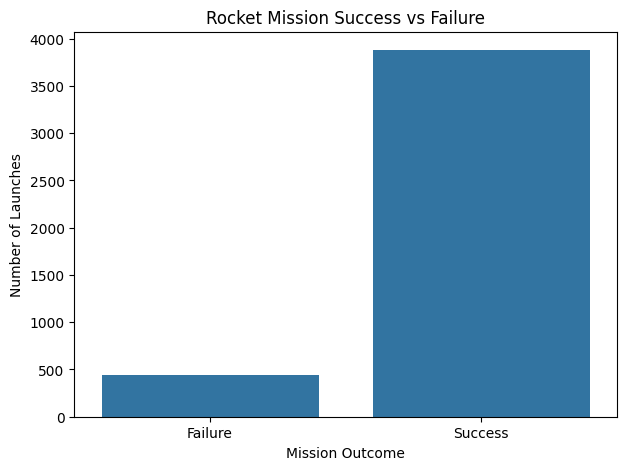

In [42]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=data,
    x="Mission_Success"
)

plt.title("Rocket Mission Success vs Failure")
plt.xlabel("Mission Outcome")
plt.ylabel("Number of Launches")

plt.xticks(
    [0, 1],
    ["Failure", "Success"]
)

plt.show()

In [43]:
yearly_analysis = data.groupby("Launch_Year").agg(
    Total_Launches=("Mission_Success", "count"),
    Successful_Launches=("Mission_Success", "sum")
)

yearly_analysis["Success_Rate"] = (
    yearly_analysis["Successful_Launches"] /
    yearly_analysis["Total_Launches"]
) * 100

print(yearly_analysis)

             Total_Launches  Successful_Launches  Success_Rate
Launch_Year                                                   
1957.0                    3                    2     66.666667
1958.0                   22                    6     27.272727
1959.0                   20                    8     40.000000
1960.0                   38                   19     50.000000
1961.0                   52                   32     61.538462
...                     ...                  ...           ...
2016.0                   88                   84     95.454545
2017.0                   90                   83     92.222222
2018.0                  117                  113     96.581197
2019.0                  107                  100     93.457944
2020.0                   63                   57     90.476190

[64 rows x 3 columns]


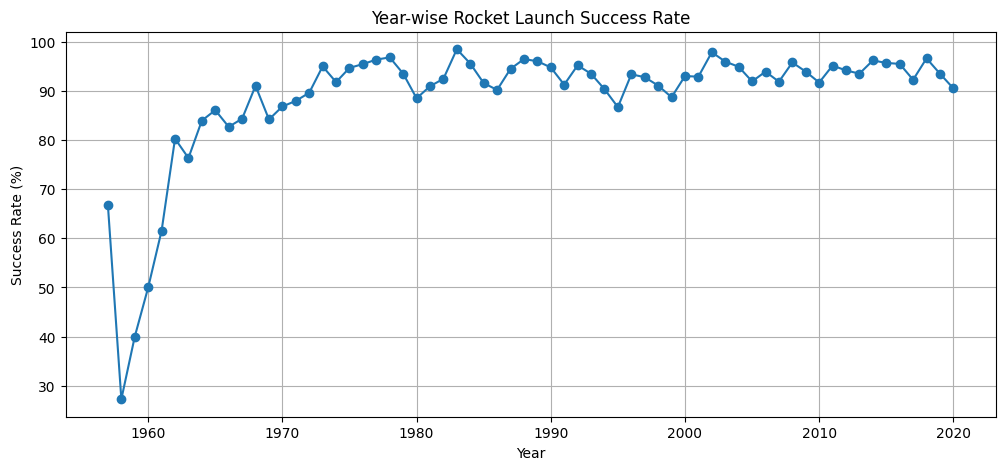

In [44]:
plt.figure(figsize=(12, 5))

plt.plot(
    yearly_analysis.index,
    yearly_analysis["Success_Rate"],
    marker="o"
)

plt.title("Year-wise Rocket Launch Success Rate")
plt.xlabel("Year")
plt.ylabel("Success Rate (%)")
plt.grid(True)

plt.show()

In [45]:
company_analysis = data.groupby("Company Name").agg(
    Total_Launches=("Mission_Success", "count"),
    Successful_Launches=("Mission_Success", "sum")
)

company_analysis["Success_Rate"] = (
    company_analysis["Successful_Launches"] /
    company_analysis["Total_Launches"]
) * 100

company_analysis = company_analysis.sort_values(
    "Total_Launches",
    ascending=False
)

company_analysis.head(15)

,Total_Launches,Successful_Launches,Success_Rate
Company Name,,,
RVSN USSR,1777,1614,90.827237
Arianespace,279,269,96.415771
General Dynamics,251,203,80.876494
CASC,251,231,92.031873
NASA,203,186,91.625616
VKS RF,201,188,93.532338
US Air Force,161,129,80.124224
ULA,140,139,99.285714
Boeing,136,131,96.323529


In [46]:
reliable_companies = company_analysis[
    company_analysis["Total_Launches"] >= 20
].sort_values(
    "Success_Rate",
    ascending=False
)

print("Top companies with at least 20 launches:")
print(reliable_companies.head(10))

Top companies with at least 20 launches:
              Total_Launches  Successful_Launches  Success_Rate
Company Name                                                   
ULA                      140                  139     99.285714
ILS                       46                   45     97.826087
Arianespace              279                  269     96.415771
Boeing                   136                  131     96.323529
Kosmotras                 22                   21     95.454545
MHI                       84                   80     95.238095
SpaceX                   100                   94     94.000000
Lockheed                  79                   74     93.670886
VKS RF                   201                  188     93.532338
Roscosmos                 55                   51     92.727273


In [47]:
location_analysis = data.groupby("Location").agg(
    Total_Launches=("Mission_Success", "count"),
    Successful_Launches=("Mission_Success", "sum")
)

location_analysis["Success_Rate"] = (
    location_analysis["Successful_Launches"] /
    location_analysis["Total_Launches"]
) * 100

location_analysis = location_analysis.sort_values(
    "Total_Launches",
    ascending=False
)

location_analysis.head(15)

,Total_Launches,Successful_Launches,Success_Rate
Location,,,
"Site 31/6, Baikonur Cosmodrome, Kazakhstan",235,220,93.617021
"Site 132/1, Plesetsk Cosmodrome, Russia",216,203,93.981481
"Site 43/4, Plesetsk Cosmodrome, Russia",202,190,94.059406
"Site 41/1, Plesetsk Cosmodrome, Russia",198,186,93.939394
"Site 1/5, Baikonur Cosmodrome, Kazakhstan",193,155,80.310881
"Site 132/2, Plesetsk Cosmodrome, Russia",174,164,94.252874
"Site 133/3, Plesetsk Cosmodrome, Russia",158,147,93.037975
"Site 43/3, Plesetsk Cosmodrome, Russia",138,131,94.927536
"LC-39A, Kennedy Space Center, Florida, USA",120,117,97.500000


In [48]:
print(data["Status Rocket"].value_counts())

Status Rocket
StatusRetired    3534
StatusActive      790
Name: count, dtype: int64


In [49]:
rocket_status_analysis = data.groupby("Status Rocket").agg(
    Total_Launches=("Mission_Success", "count"),
    Successful_Launches=("Mission_Success", "sum")
)

rocket_status_analysis["Success_Rate"] = (
    rocket_status_analysis["Successful_Launches"] /
    rocket_status_analysis["Total_Launches"]
) * 100

print(rocket_status_analysis)

               Total_Launches  Successful_Launches  Success_Rate
Status Rocket                                                   
StatusActive              790                  736     93.164557
StatusRetired            3534                 3143     88.936050


In [50]:
data = data.sort_values("Datum").reset_index(drop=True)

print(data[["Datum", "Company Name", "Mission_Success"]].head(10))

                      Datum Company Name  Mission_Success
0 1957-10-04 19:28:00+00:00    RVSN USSR                1
1 1957-11-03 02:30:00+00:00    RVSN USSR                1
2 1957-12-06 16:44:00+00:00      US Navy                0
3 1958-02-01 03:48:00+00:00         AMBA                1
4 1958-02-05 07:33:00+00:00      US Navy                0
5 1958-03-05 18:27:00+00:00         AMBA                0
6 1958-03-17 12:15:00+00:00      US Navy                1
7 1958-03-26 17:38:00+00:00         AMBA                1
8 1958-04-27 09:01:00+00:00    RVSN USSR                0
9 1958-04-28 02:53:00+00:00      US Navy                0


In [51]:
data["Company_Previous_Launches"] = (
    data.groupby("Company Name").cumcount()
)

data["Company_Previous_Successes"] = (
    data.groupby("Company Name")["Mission_Success"]
    .cumsum()
    .shift(1)
    .fillna(0)
)

data["Company_Previous_Success_Rate"] = np.where(
    data["Company_Previous_Launches"] > 0,
    (
        data["Company_Previous_Successes"] /
        data["Company_Previous_Launches"]
    ) * 100,
    0
)

data[
    [
        "Company Name",
        "Company_Previous_Launches",
        "Company_Previous_Successes",
        "Company_Previous_Success_Rate"
    ]
].head(20)

,Company Name,Company_Previous_Launches,Company_Previous_Successes,Company_Previous_Success_Rate
0,RVSN USSR,0,0.0,0.000000
1,RVSN USSR,1,1.0,100.000000
2,US Navy,0,2.0,0.000000
3,AMBA,0,0.0,0.000000
4,US Navy,1,1.0,100.000000
5,AMBA,1,0.0,0.000000
6,US Navy,2,1.0,50.000000
7,AMBA,2,1.0,50.000000
8,RVSN USSR,2,2.0,100.000000
9,US Navy,3,2.0,66.666667


In [52]:
data["Location_Previous_Launches"] = (
    data.groupby("Location").cumcount()
)

data["Location_Previous_Successes"] = (
    data.groupby("Location")["Mission_Success"]
    .cumsum()
    .shift(1)
    .fillna(0)
)

data["Location_Previous_Success_Rate"] = np.where(
    data["Location_Previous_Launches"] > 0,
    (
        data["Location_Previous_Successes"] /
        data["Location_Previous_Launches"]
    ) * 100,
    0
)

data[
    [
        "Location",
        "Location_Previous_Launches",
        "Location_Previous_Success_Rate"
    ]
].head(20)

,Location,Location_Previous_Launches,Location_Previous_Success_Rate
0,"Site 1/5, Baikonur Cosmodrome, Kazakhstan",0,0.000000
1,"Site 1/5, Baikonur Cosmodrome, Kazakhstan",1,100.000000
2,"LC-18A, Cape Canaveral AFS, Florida, USA",0,0.000000
3,"LC-26A, Cape Canaveral AFS, Florida, USA",0,0.000000
4,"LC-18A, Cape Canaveral AFS, Florida, USA",1,100.000000
5,"LC-26A, Cape Canaveral AFS, Florida, USA",1,0.000000
6,"LC-18A, Cape Canaveral AFS, Florida, USA",2,50.000000
7,"LC-5, Cape Canaveral AFS, Florida, USA",0,0.000000
8,"Site 1/5, Baikonur Cosmodrome, Kazakhstan",2,50.000000
9,"LC-18A, Cape Canaveral AFS, Florida, USA",3,66.666667


In [53]:
# Remove rows where the launch date is missing
data = data.dropna(subset=["Datum"]).copy()

# Recalculate historical company features correctly
data["Company_Previous_Launches"] = (
    data.groupby("Company Name").cumcount()
)

data["Company_Previous_Successes"] = (
    data.groupby("Company Name")["Mission_Success"]
    .transform(lambda x: x.cumsum().shift(1))
    .fillna(0)
)

data["Company_Previous_Success_Rate"] = np.where(
    data["Company_Previous_Launches"] > 0,
    (data["Company_Previous_Successes"] /
     data["Company_Previous_Launches"]) * 100,
    0
)

# Recalculate historical location features correctly
data["Location_Previous_Launches"] = (
    data.groupby("Location").cumcount()
)

data["Location_Previous_Successes"] = (
    data.groupby("Location")["Mission_Success"]
    .transform(lambda x: x.cumsum().shift(1))
    .fillna(0)
)

data["Location_Previous_Success_Rate"] = np.where(
    data["Location_Previous_Launches"] > 0,
    (data["Location_Previous_Successes"] /
     data["Location_Previous_Launches"]) * 100,
    0
)

print("Historical features recalculated successfully!")
print("Remaining missing values:")
print(data.isnull().sum())

Historical features recalculated successfully!
Remaining missing values:
Company Name                         0
Location                             0
Datum                                0
Detail                               0
Status Rocket                        0
Rocket                            3240
Status Mission                       0
Mission_Success                      0
Launch_Year                          0
Launch_Month                         0
Company_Previous_Launches            0
Company_Previous_Successes           0
Company_Previous_Success_Rate        0
Location_Previous_Launches           0
Location_Previous_Successes          0
Location_Previous_Success_Rate       0
dtype: int64


In [54]:
features = [
    "Company Name",
    "Location",
    "Launch_Year",
    "Launch_Month",
    "Status Rocket",
    "Company_Previous_Launches",
    "Company_Previous_Success_Rate",
    "Location_Previous_Launches",
    "Location_Previous_Success_Rate"
]

target = "Mission_Success"

X = data[features].copy()
y = data[target].copy()

print("Features used:")
print(features)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Features used:
['Company Name', 'Location', 'Launch_Year', 'Launch_Month', 'Status Rocket', 'Company_Previous_Launches', 'Company_Previous_Success_Rate', 'Location_Previous_Launches', 'Location_Previous_Success_Rate']

Feature shape: (4198, 9)
Target shape: (4198,)


In [55]:
print(X.head())

print("\nMissing values:")
print(X.isnull().sum())

  Company Name                                   Location  Launch_Year  \
0    RVSN USSR  Site 1/5, Baikonur Cosmodrome, Kazakhstan       1957.0   
1    RVSN USSR  Site 1/5, Baikonur Cosmodrome, Kazakhstan       1957.0   
2      US Navy   LC-18A, Cape Canaveral AFS, Florida, USA       1957.0   
3         AMBA   LC-26A, Cape Canaveral AFS, Florida, USA       1958.0   
4      US Navy   LC-18A, Cape Canaveral AFS, Florida, USA       1958.0   

   Launch_Month  Status Rocket  Company_Previous_Launches  \
0          10.0  StatusRetired                          0   
1          11.0  StatusRetired                          1   
2          12.0  StatusRetired                          0   
3           2.0  StatusRetired                          0   
4           2.0  StatusRetired                          1   

   Company_Previous_Success_Rate  Location_Previous_Launches  \
0                            0.0                           0   
1                          100.0                           1

In [56]:
split_index = int(len(data) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining period:")
print(data["Datum"].iloc[0], "to", data["Datum"].iloc[split_index - 1])

print("\nTesting period:")
print(data["Datum"].iloc[split_index], "to", data["Datum"].iloc[-1])

Training samples: 3358
Testing samples: 840

Training period:
1957-10-04 19:28:00+00:00 to 2007-07-02 19:38:00+00:00

Testing period:
2007-07-05 20:08:00+00:00 to 2020-08-07 05:12:00+00:00


In [57]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = [
    "Company Name",
    "Location",
    "Status Rocket"
]

numerical_features = [
    "Launch_Year",
    "Launch_Month",
    "Company_Previous_Launches",
    "Company_Previous_Success_Rate",
    "Location_Previous_Launches",
    "Location_Previous_Success_Rate"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

print("Preprocessing setup completed successfully!")

Preprocessing setup completed successfully!


In [58]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced"
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [59]:
from sklearn.tree import DecisionTreeClassifier

tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=8,
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)

tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_test)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [60]:
from sklearn.ensemble import RandomForestClassifier

forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=10,
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)

forest_model.fit(X_train, y_train)

forest_predictions = forest_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [61]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_model(name, y_true, predictions):
    accuracy = accuracy_score(y_true, predictions)
    precision = precision_score(y_true, predictions, zero_division=0)
    recall = recall_score(y_true, predictions, zero_division=0)
    f1 = f1_score(y_true, predictions, zero_division=0)

    return {
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }

results = []

results.append(
    evaluate_model("Logistic Regression", y_test, logistic_predictions)
)

results.append(
    evaluate_model("Decision Tree", y_test, tree_predictions)
)

results.append(
    evaluate_model("Random Forest", y_test, forest_predictions)
)

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.780952,0.963415,0.797980,0.872928
1,Decision Tree,0.764286,0.955521,0.786616,0.862881
2,Random Forest,0.919048,0.961735,0.952020,0.956853


Confusion Matrix:
[[ 18  30]
 [ 38 754]]


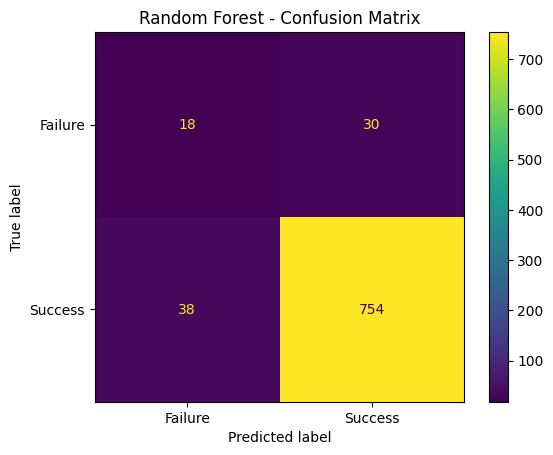

In [62]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, forest_predictions)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Failure", "Success"]
)

disp.plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [63]:
from sklearn.metrics import classification_report

print("Random Forest Classification Report:\n")

print(
    classification_report(
        y_test,
        forest_predictions,
        target_names=["Failure", "Success"],
        zero_division=0
    )
)

Random Forest Classification Report:

              precision    recall  f1-score   support

     Failure       0.32      0.38      0.35        48
     Success       0.96      0.95      0.96       792

    accuracy                           0.92       840
   macro avg       0.64      0.66      0.65       840
weighted avg       0.93      0.92      0.92       840



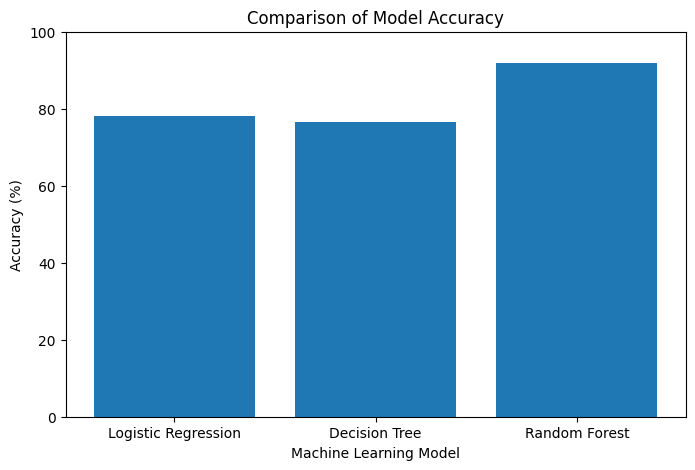

In [64]:
results_percentage = results_df.copy()

for column in ["Accuracy", "Precision", "Recall", "F1 Score"]:
    results_percentage[column] = (
        results_percentage[column] * 100
    ).round(2)

models = results_percentage["Model"]
accuracies = results_percentage["Accuracy"]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies)

plt.ylabel("Accuracy (%)")
plt.xlabel("Machine Learning Model")
plt.title("Comparison of Model Accuracy")
plt.ylim(0, 100)

plt.show()

In [65]:
# ==========================================
# NEW MISSION PREDICTION
# ==========================================

company = input("Enter Company Name: ")
location = input("Enter Launch Location: ")
year = int(input("Enter Launch Year: "))
month = int(input("Enter Launch Month (1-12): "))
rocket_status = input("Enter Rocket Status (StatusActive/StatusRetired): ")

# Get historical information from the dataset
company_history = data[data["Company Name"] == company]

location_history = data[data["Location"] == location]

if len(company_history) > 0:
    company_previous_launches = len(company_history)
    company_success_rate = (
        company_history["Mission_Success"].mean() * 100
    )
else:
    company_previous_launches = 0
    company_success_rate = 0

if len(location_history) > 0:
    location_previous_launches = len(location_history)
    location_success_rate = (
        location_history["Mission_Success"].mean() * 100
    )
else:
    location_previous_launches = 0
    location_success_rate = 0

# Create mission data
mentor_mission = pd.DataFrame({
    "Company Name": [company],
    "Location": [location],
    "Launch_Year": [year],
    "Launch_Month": [month],
    "Status Rocket": [rocket_status],
    "Company_Previous_Launches": [company_previous_launches],
    "Company_Previous_Success_Rate": [company_success_rate],
    "Location_Previous_Launches": [location_previous_launches],
    "Location_Previous_Success_Rate": [location_success_rate]
})

print("\nHistorical information calculated:")
print("Previous Company Launches:", company_previous_launches)
print("Previous Company Success Rate:",
      round(company_success_rate, 2), "%")
print("Previous Location Launches:", location_previous_launches)
print("Previous Location Success Rate:",
      round(location_success_rate, 2), "%")


Historical information calculated:
Previous Company Launches: 100
Previous Company Success Rate: 94.0 %
Previous Location Launches: 0
Previous Location Success Rate: 0 %


In [66]:
prediction = forest_model.predict(example_mission)

if prediction[0] == 1:
    print("Predicted Mission Outcome: SUCCESS")
else:
    print("Predicted Mission Outcome: FAILURE")

Predicted Mission Outcome: SUCCESS


In [67]:
prediction_probability = forest_model.predict_proba(example_mission)

print("Probability of Failure:", round(prediction_probability[0][0] * 100, 2), "%")
print("Probability of Success:", round(prediction_probability[0][1] * 100, 2), "%")

Probability of Failure: 35.29 %
Probability of Success: 64.71 %
